# 02 — Sélection des variables

## Partie A — Screening naïf : qu'est-ce qui n'a pas sa place dans X ?

**Question :** parmi les colonnes de `dataset_v2.csv`, lesquelles ne doivent pas être des prédicteurs (vecteur X) d'un modèle de régression de Q10 ?

**Principe :** une colonne n'entre dans X que si elle remplit trois critères :
1. **Disponible partout** : elle existe en carte mondiale. Sinon, impossible de produire la carte de Q10 pour ORCHIDEE.
2. **Plausible physiquement** : elle peut agir sur Q10 (climat, sol), et n'est pas un artefact de l'échantillonnage.
3. **Exploitable statistiquement** : pas de valeurs manquantes, non constante, non redondante avec une autre variable.

Chaque étape suit la structure : **Objectif** → **Raisonnement** → code → **Constat** / **Décision**.

In [1]:
# Imports : pandas pour les données, matplotlib pour les graphiques, valeur fixe de référence (src/protocole.py)
import sys
sys.path.append("..")
import pandas as pd
import matplotlib.pyplot as plt
from src.protocole import Q10_REFERENCE

In [2]:
# Chargement de la version de référence du dataset (une ligne par site)
df = pd.read_csv("../data/dataset_v2.csv")
df.head()

,site,source,study,Q10,n_mesures,lat,lon,MAT_public,MAP_public,pH_public,N515
0,paper_66,paper,paper_47,2.155653,1,-37.422361,144.094194,12.120522,636.457930,5.749557,2431.892349
1,paper_34,paper,paper_25,3.230911,1,14.583333,98.866667,24.521796,1572.758221,5.579726,2371.518618
2,paper_69,paper,paper_49,2.193185,1,21.160000,101.040000,21.166023,1826.576010,5.267783,2658.456495
3,dig_Zhao2021_Xishuangbanna,figure,dig_Zhao2021,2.589000,1,21.617000,101.583000,20.573714,1776.573980,5.152625,2276.136182
4,paper_80,paper,paper_57,2.012824,1,22.166667,106.833333,21.297576,1569.578627,5.924567,1649.934092


### Étape 1 — Rôle de chaque colonne (critère 1)

**Objectif :** écarter les colonnes qui, par nature, ne peuvent pas être des prédicteurs.

**Raisonnement :** pour prédire Q10 en un point quelconque de la planète, le modèle ne peut utiliser que des informations disponibles en ce point, donc des cartes mondiales.

| Colonne | Rôle | En carte mondiale ? | Décision |
|---|---|---|---|
| `site`, `study` | identifiants | non | **exclure** : un modèle qui les utiliserait apprendrait des sites par cœur, sans rien pouvoir prédire ailleurs |
| `source` | métadonnée : base d'origine de la mesure | non | **exclure** : utile pour contrôler des biais de mesure, pas pour prédire |
| `n_mesures` | métadonnée : nombre de mesures agrégées | non | **exclure** : pourra servir de *poids* (un Q10 moyen sur 9 mesures est plus fiable) |
| `Q10` | cible | — | c'est y |
| `lat`, `lon` | coordonnées | oui | à examiner (étape 2) |
| `MAT_public`, `MAP_public`, `pH_public`, `N515` | climat et sol | oui | candidats (étape 3) |

### Étape 2 — Latitude et longitude (critère 2)

**Objectif :** décider si les coordonnées entrent dans X.

**Raisonnement :** elles sont disponibles partout (critère 1 rempli), mais ce ne sont pas des moteurs physiques : la latitude n'agit sur Q10 qu'à travers le climat et le sol, que l'on mesure déjà. Hacopian a exclu la latitude pour cette raison. Le risque est que le modèle apprenne **où se trouvent nos sites** plutôt que **ce qui fait varier Q10**, et qu'il soit perdu dans les régions qui ne sont pas représentées. On regarde donc la répartition géographique des sites.

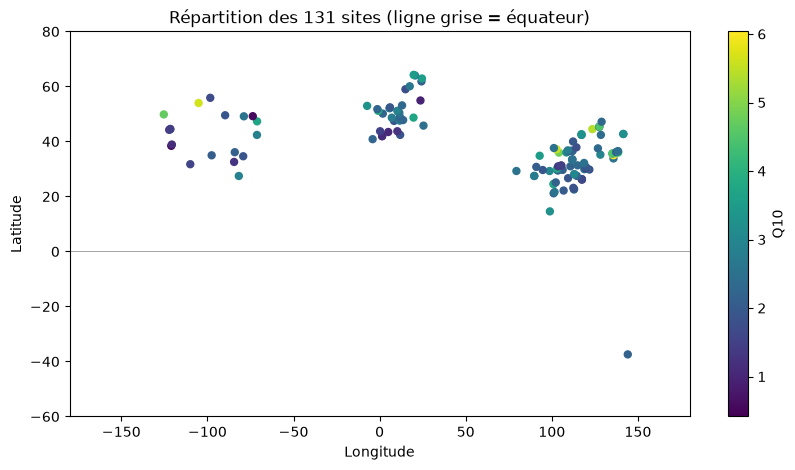

In [3]:
# Carte simple des sites (longitude, latitude), couleur = Q10
plt.figure(figsize=(10, 5))
plt.scatter(df.lon, df.lat, c=df.Q10, s=25)
plt.colorbar(label="Q10")
plt.axhline(0, c="grey", lw=0.5)
plt.xlim(-180, 180); plt.ylim(-60, 80)
plt.xlabel("Longitude"); plt.ylabel("Latitude"); plt.title("Répartition des 131 sites (ligne grise = équateur)")
plt.show()

In [4]:
# Part des sites dans l'hémisphère Nord, en Asie de l'Est (lon 73–146°, lat 18–54°) et en zone tropicale
print(f"Hémisphère Nord : {(df.lat > 0).mean():.0%}")
print(f"Asie de l'Est : {(df.lon.between(73, 146) & df.lat.between(18, 54)).mean():.0%}")
print(f"Zone tropicale (|lat| < 23.5°) : {(df.lat.abs() < 23.5).sum()} sites")

Hémisphère Nord : 99%
Asie de l'Est : 58%
Zone tropicale (|lat| < 23.5°) : 7 sites


In [5]:
# Corrélation entre |latitude| et MAT : la latitude est-elle un simple relais du climat ?
print(f"r = {df.lat.abs().corr(df.MAT_public):.2f}")

r = -0.64


**Constat :** les sites forment trois groupes (Amérique du Nord, Europe, Asie de l'Est). 99 % sont dans l'hémisphère Nord (un seul site au Sud, en Australie), 58 % en Asie de l'Est, et seulement 7 en zone tropicale. Il n'y a aucun site en Afrique ni en Amérique du Sud. La valeur absolue de la latitude est fortement liée à MAT (r = −0.64) : elle n'apporte donc pas d'information physique nouvelle.

**Décision (équipe) : conserver `lat` et `lon` comme candidats pour l'instant.** Leur effet sur Q10 n'est pas direct, mais il existe probablement : les coordonnées peuvent porter des informations qu'aucune autre variable ne mesure (végétation, histoire des sols, communautés microbiennes régionales…). La sélection rigoureuse (LASSO et validation croisée spatiale) dira si elles améliorent vraiment les prédictions.

**Points de vigilance**, issus des constats ci-dessus :
- l'échantillon est très concentré : la validation croisée devra être groupée par zone géographique, sinon l'apport des coordonnées sera surestimé ;
- sur la carte mondiale, les prédictions dans les zones sans aucun site (hémisphère Sud, Afrique, Amérique du Sud) seront à interpréter avec prudence ;
- la part de la prédiction portée par les coordonnées restera figée si le climat change.

### Étape 3 — Contrôles statistiques des candidats (critère 3)

**Objectif :** vérifier que les 6 candidats (coordonnées, climat, sol) sont exploitables.

**Raisonnement :** on vérifie, dans l'ordre : valeurs manquantes et valeurs distinctes, forme des distributions, redondance entre candidats, puis lien avec Q10.

In [6]:
# Variables candidates : coordonnées, climat et sol, toutes disponibles en carte mondiale
X_cols = ["lat", "lon", "MAT_public", "MAP_public", "pH_public", "N515"]

In [7]:
# Nombre de valeurs manquantes et de valeurs distinctes par candidat
pd.DataFrame({"manquantes": df[X_cols].isna().sum(), "distinctes": df[X_cols].nunique()})

,manquantes,distinctes
lat,0,130
lon,0,129
MAT_public,0,131
MAP_public,0,131
pH_public,0,131
N515,0,131


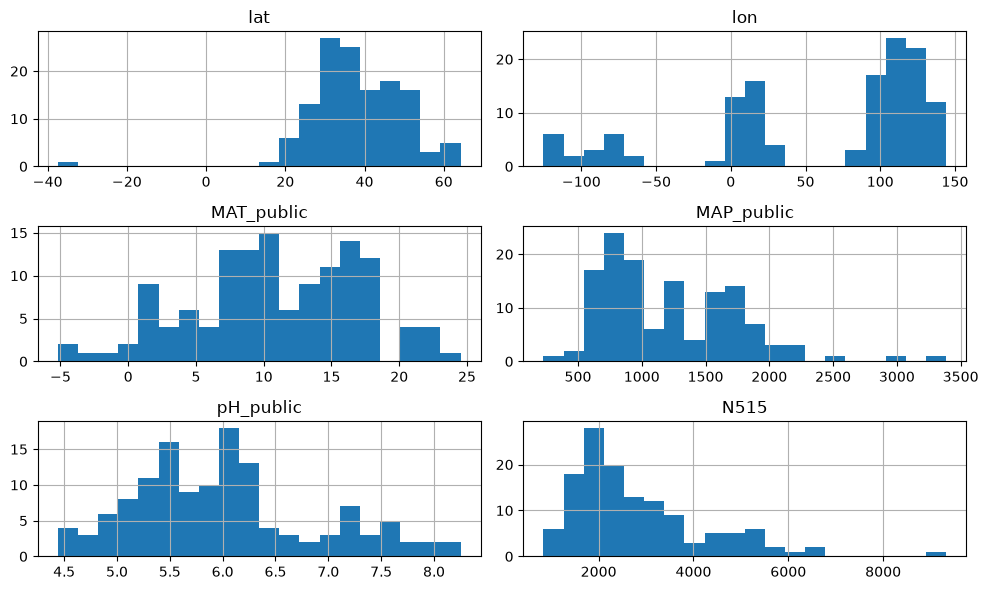

In [8]:
# Distribution de chaque candidat
df[X_cols].hist(bins=20, figsize=(10, 6))
plt.tight_layout(); plt.show()

In [9]:
# Asymétrie des distributions (0 = symétrique ; > 1 = longue queue à droite)
df[X_cols].skew().round(2)

lat          -1.53
lon          -0.94
MAT_public   -0.24
MAP_public    1.00
pH_public     0.65
N515          1.43
dtype: float64

**Constat :** aucune valeur manquante, et presque autant de valeurs distinctes que de sites (quelques sites partagent la même latitude ou la même longitude). MAP et N515 ont une longue queue à droite (asymétrie 1.0 et 1.4) : un passage au logarithme pourra aider les modèles linéaires. C'est une question de transformation, pas d'exclusion, à trancher à l'étape des modèles. `lat` a une queue vers le bas (−1.5), due au seul site de l'hémisphère Sud. La distribution de `lon` a trois paquets (Amérique du Nord, Europe, Asie de l'Est) : elle décrit des régions plus qu'un gradient continu.

In [10]:
# Corrélations entre candidats (Spearman : robuste aux valeurs extrêmes et aux relations non linéaires monotones)
df[X_cols].corr("spearman").round(2)

,lat,lon,MAT_public,MAP_public,pH_public,N515
lat,1.00,-0.43,-0.68,-0.57,-0.02,0.39
lon,-0.43,1.00,0.12,0.27,-0.01,-0.09
MAT_public,-0.68,0.12,1.00,0.47,-0.11,-0.55
MAP_public,-0.57,0.27,0.47,1.00,-0.51,0.14
pH_public,-0.02,-0.01,-0.11,-0.51,1.00,-0.49
N515,0.39,-0.09,-0.55,0.14,-0.49,1.00


**Constat :** la plus forte corrélation entre candidats est de 0.68 en valeur absolue (lat–MAT), sous le seuil usuel de 0.8 à partir duquel deux variables sont jugées redondantes. **Aucun candidat n'est exclu pour redondance.** Ces corrélations moyennes rendront cependant les coefficients d'un modèle linéaire instables, comme le notait déjà Hacopian : c'est un argument pour la régularisation (Ridge, LASSO).

In [11]:
# Corrélation de chaque candidat avec Q10 (Pearson : lien linéaire ; Spearman : lien monotone)
pd.DataFrame({"pearson": df[X_cols].corrwith(df.Q10), "spearman": df[X_cols].corrwith(df.Q10, method="spearman")}).round(2)

,pearson,spearman
lat,0.09,0.09
lon,0.21,0.23
MAT_public,-0.26,-0.30
MAP_public,-0.00,-0.04
pH_public,-0.02,-0.12
N515,0.25,0.35


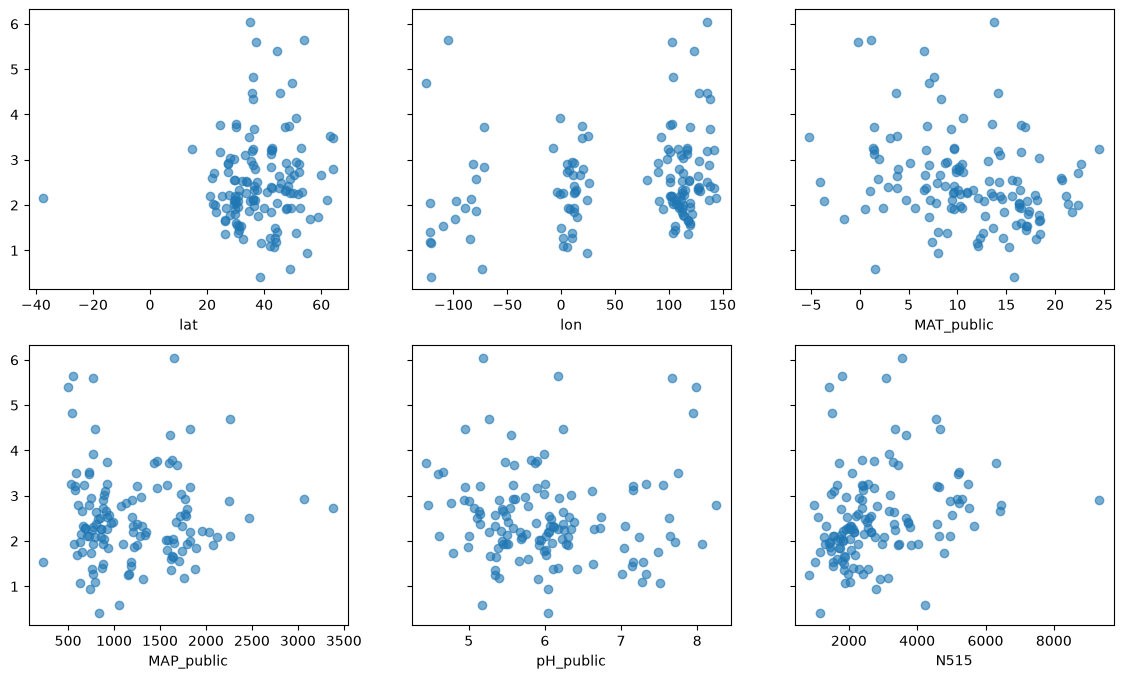

In [12]:
# Q10 en fonction de chaque candidat
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for ax, col in zip(axes.flat, X_cols):
    ax.scatter(df[col], df.Q10, alpha=0.6); ax.set_xlabel(col)
plt.show()

**Constat :** les nuages de points sont très dispersés : même les liens les plus nets sont faibles. MAT (Spearman −0.30) et N515 (+0.35) ont un lien visible avec Q10, `lon` un lien plus faible (+0.23). MAP (−0.04), pH (−0.12) et `lat` (+0.09) n'en ont presque aucun pris isolément. Pour le pH, c'est différent de Hacopian (+0.30) ; nos données ne sont pas les mêmes (sources ajoutées, pas de pondération par R², agrégation par site).

### Étape 4 — Faut-il exclure MAP et pH ?

**Objectif :** vérifier si un lien faible avec Q10 pris isolément suffit à exclure une variable.

**Raisonnement :** une variable peut ne montrer aucun lien seule et en avoir un une fois les autres prises en compte. C'est le cas si son effet est masqué par une variable avec laquelle elle varie (ici, MAP et MAT sont corrélées à 0.47 : les régions humides sont souvent plus chaudes). On compare les coefficients d'une régression linéaire sur variables centrées-réduites, pour qu'ils soient comparables entre variables.

In [13]:
# Import : régression linéaire
from sklearn.linear_model import LinearRegression

In [14]:
# Candidats centrés-réduits (moyenne 0, écart-type 1)
Z = (df[X_cols] - df[X_cols].mean()) / df[X_cols].std()

In [15]:
# Coefficient de MAP seul, puis de MAT et MAP ensemble
print(f"MAP seul : {LinearRegression().fit(Z[['MAP_public']], df.Q10).coef_[0]:.3f}")
print("MAT + MAP :", LinearRegression().fit(Z[["MAT_public", "MAP_public"]], df.Q10).coef_.round(2))

MAP seul : -0.002
MAT + MAP : [-0.31  0.12]


In [16]:
# Coefficients de tous les candidats ensemble
pd.Series(LinearRegression().fit(Z, df.Q10).coef_, index=X_cols).round(2)

lat           0.03
lon           0.30
MAT_public   -0.18
MAP_public   -0.05
pH_public     0.00
N515          0.23
dtype: float64

**Constat :**
- Seul, MAP a un coefficient nul. Une fois MAT prise en compte, il devient positif (+0.12) : l'effet négatif de MAT masquait celui de MAP. Le modèle publié par Hacopian a lui aussi un coefficient de MAP positif, malgré un lien négatif pris isolément.
- Avec les 6 candidats, MAP retombe à −0.05 et le pH à 0.00, tandis que `lon` obtient le plus fort coefficient (+0.30). Les coefficients changent donc fortement selon les variables présentes. C'est typique de variables corrélées entre elles quand on a peu de données.
- `lon` distingue surtout l'Asie de l'Est (lon > 73°, Q10 moyen 2.67) des autres régions (2.28). Reste à savoir, en validation croisée spatiale, s'il s'agit d'un vrai signal régional ou d'un effet d'échantillonnage (par exemple des méthodes de mesure propres à certaines études).

Attention : ces coefficients sont calculés sur les données d'entraînement. Ils montrent qu'**on ne peut trancher ni variable par variable, ni sur un lien pris isolément**, mais pas quelles variables améliorent les prédictions sur de nouveaux sites.

**Décision : aucun candidat n'est exclu à ce stade.** Leur utilité sera tranchée par une méthode rigoureuse (LASSO, validation croisée spatiale) dans la partie B, après enrichissement du dataset.

## Résumé de la partie A

| Colonne | Décision | Raison |
|---|---|---|
| `site`, `study`, `source`, `n_mesures` | exclues de X | pas de carte mondiale (`n_mesures` pourra servir de poids) |
| `Q10` | cible y | — |
| `lat`, `lon` | **candidats retenus** (décision de l'équipe) | effet indirect mais probable ; vigilance : échantillon très concentré géographiquement |
| `MAT_public`, `MAP_public`, `pH_public`, `N515` | **candidats retenus** | disponibles partout, plausibles, sans manquants ni redondance |

**Bilan :** 6 candidats pour 131 sites. Pistes ouvertes : passage au log de MAP et N515, pondération par `n_mesures`. Le dataset est enrichi de nouvelles variables dans `03_enrichissement_donnees.ipynb` avant la sélection rigoureuse (partie B).

## Partie B — Préparation de la sélection rigoureuse

À partir d'ici, on travaille sur `dataset_v3.csv` (12 candidats, cf. `03_enrichissement_donnees.ipynb`).

### Étape 1 — Que faire des biomes représentés par un seul site ?

**Objectif :** décider à quel biome rattacher les deux biomes qui n'ont qu'un site.

**Raisonnement :** un modèle ne peut rien apprendre de fiable d'une catégorie qui ne contient qu'un site. En validation croisée, cette catégorie est d'ailleurs inconnue du modèle chaque fois que son unique site est en test. Proposition initiale : forêts tropicales de conifères → forêts tropicales humides, et déserts → méditerranéen. On la teste avec trois critères, **sans utiliser Q10 pour décider** (sinon on construirait une variable explicative à partir de la cible, sur un seul site) :
1. proximité environnementale (climat et sol) ;
2. cohérence écologique ;
3. effet sur la validation croisée.

On regarde ensuite ce que ce choix implique pour la carte mondiale.

In [17]:
# Chargement de la version 3 (dataset enrichi) : à partir d'ici, df désigne cette version
df = pd.read_csv("../data/dataset_v3.csv")

In [18]:
# Les deux biomes représentés par un seul site, et ces sites
rares = ["Tropical & Subtropical Coniferous Forests", "Deserts & Xeric Shrublands"]
sites_rares = df[df.biome.isin(rares)]
sites_rares[["site", "biome", "lat", "lon", "MAT_public", "MAP_public", "SWC_warm_rel", "Q10"]]

,site,biome,lat,lon,MAT_public,MAP_public,SWC_warm_rel,Q10
22,961_IN-KAI,Tropical & Subtropical Coniferous Forests,29.27000,79.43000,20.749229,1713.670137,1.105653,2.557778
42,new_cosore_SCOTT_WKG_trenched,Deserts & Xeric Shrublands,31.73652,-109.94185,17.160577,229.649339,0.978055,1.545448


#### Critère 1 — Proximité environnementale

On centre-réduit les 9 variables environnementales (climat et sol), puis on mesure la distance de chaque site rare au centre de chaque biome (moyenne de ses sites). Plus la distance est faible, plus le site ressemble au biome. On le fait sur toutes les variables, puis sur le climat seul.

In [19]:
# Variables environnementales (climat et sol), centrées-réduites
env = ["MAT_public", "MAP_public", "pH_public", "N515", "clay", "sand", "CN", "SWC_mean", "SWC_warm_rel"]
Z = (df[env] - df[env].mean()) / df[env].std()

In [20]:
# Fonction : distance de chaque site rare au centre de chaque biome (hors biomes rares), sur les variables choisies
def distances(cols):
    centres = Z.loc[~df.biome.isin(rares), cols].groupby(df.biome).mean()
    return pd.DataFrame({b: ((centres - Z.loc[df.biome == b, cols].iloc[0]) ** 2).sum(axis=1) ** 0.5 for b in rares}).round(2)

In [21]:
# Distances sur toutes les variables environnementales (triées pour le site du désert)
distances(env).sort_values(rares[1])

,Tropical & Subtropical Coniferous Forests,Deserts & Xeric Shrublands
biome,,
"Temperate Grasslands, Savannas & Shrublands",3.18,2.41
"Mediterranean Forests, Woodlands & Scrub",4.34,3.32
Temperate Broadleaf & Mixed Forests,2.16,3.45
Montane Grasslands & Shrublands,4.56,3.68
Tropical & Subtropical Moist Broadleaf Forests,1.28,4.37
Temperate Conifer Forests,2.98,4.51
Boreal Forests/Taiga,4.46,4.88


In [22]:
# Distances sur le climat seul : température, précipitations, humidité du sol
distances(["MAT_public", "MAP_public", "SWC_mean", "SWC_warm_rel"]).sort_values(rares[1])

,Tropical & Subtropical Coniferous Forests,Deserts & Xeric Shrublands
biome,,
"Temperate Grasslands, Savannas & Shrublands",2.24,1.62
Temperate Broadleaf & Mixed Forests,2.15,2.41
"Mediterranean Forests, Woodlands & Scrub",4.17,2.82
Boreal Forests/Taiga,3.64,2.83
Tropical & Subtropical Moist Broadleaf Forests,0.60,3.23
Montane Grasslands & Shrublands,4.03,3.28
Temperate Conifer Forests,2.78,3.36


**Constat :**
- **Site indien** : le biome le plus proche est, de loin, celui des forêts tropicales humides (1.28, contre 2.16 pour le suivant ; 0.60 sur le climat seul).
- **Site d'Arizona** : le biome le plus proche est celui des **prairies, savanes et matorrals tempérés** (2.41 ; 1.62 sur le climat). Le méditerranéen n'arrive que deuxième sur toutes les variables (3.32), et troisième sur le climat (2.82).
- Le site d'Arizona reste loin de tous les biomes (2.41 au mieux, contre 1.28 pour le site indien) : c'est le site le plus sec du dataset (230 mm/an), et aucun biome ne le représente vraiment.

#### Critère 2 — Cohérence écologique

On regarde l'écorégion précise de chaque site (plus fine que le biome), puis le régime hydrique, qui est ce qui définit le biome méditerranéen : des étés secs et des pluies d'hiver.

In [23]:
# Import : geopandas pour lire la carte des écorégions
import geopandas as gpd

In [24]:
# Écorégion RESOLVE des deux sites rares
eco = gpd.read_file("../data/externe/Ecoregions2017.zip", columns=["ECO_NAME"])
points = gpd.GeoDataFrame(sites_rares[["site"]], geometry=gpd.points_from_xy(sites_rares.lon, sites_rares.lat), crs="EPSG:4326")
gpd.sjoin(points, eco)[["site", "ECO_NAME"]]

,site,ECO_NAME
22,961_IN-KAI,Himalayan subtropical pine forests
42,new_cosore_SCOTT_WKG_trenched,Chihuahuan desert


In [25]:
# Médianes des précipitations et de l'humidité relative estivale dans les deux biomes candidats pour le désert
candidats = ["Mediterranean Forests, Woodlands & Scrub", "Temperate Grasslands, Savannas & Shrublands"]
df[df.biome.isin(candidats)].groupby("biome")[["MAP_public", "SWC_warm_rel"]].median().round(2)

,MAP_public,SWC_warm_rel
biome,,
"Mediterranean Forests, Woodlands & Scrub",788.98,0.61
"Temperate Grasslands, Savannas & Shrublands",853.49,0.96


**Constat :**
- **Site indien** : « Himalayan subtropical pine forests », des forêts de pins du piémont himalayen sous climat de mousson, comme les forêts tropicales humides voisines. Le rattachement est cohérent.
- **Site d'Arizona** : « Chihuahuan desert ». Le site lui-même (Walnut Gulch, Kendall) est une prairie semi-aride arrosée par la mousson d'été. Son `SWC_warm_rel` vaut 0.98 : pas de sécheresse estivale relative. C'est l'inverse du méditerranéen (0.61, été sec), et c'est proche des prairies tempérées (0.96). Par sa végétation (prairie) comme par son régime hydrique, il ressemble aux prairies, savanes et matorrals tempérés, pas au méditerranéen.

#### Critère 3 — Effet sur la validation croisée

On compare une régression Ridge (linéaire, régularisée) sur les 9 variables environnementales, sans biome puis avec le biome encodé en one-hot selon chacun des deux rattachements possibles du désert. Validation croisée à 5 plis répétée 20 fois, avec les mêmes découpages pour toutes les variantes. Le découpage est aléatoire par site : cela suffit pour comparer des variantes entre elles, pas pour juger de la généralisation à de nouvelles régions.

In [26]:
# Imports : Ridge, mise à l'échelle, chaîne de traitement, modèle de référence (moyenne), validation croisée répétée
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import RepeatedKFold, cross_val_score

In [27]:
# Fonction : RMSE de validation croisée (5 plis × 20 répétitions, découpages identiques) d'un modèle sur un tableau X
def rmse_cv(modele, X):
    return -cross_val_score(modele, X, df.Q10, cv=RepeatedKFold(n_splits=5, n_repeats=20, random_state=0), scoring="neg_root_mean_squared_error")

In [28]:
# Ridge sur variables centrées-réduites, pénalité choisie par validation interne
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30)))

In [29]:
# Fonction : biome encodé en one-hot après regroupement (dictionnaire biome rare → biome de rattachement)
onehot = lambda regroupement: pd.get_dummies(df.biome.replace(regroupement), dtype=float)

In [30]:
# RMSE moyen : moyenne seule, Ridge sans biome, Ridge avec chacun des deux rattachements du désert
tropical = "Tropical & Subtropical Moist Broadleaf Forests"
scores = {
    "moyenne seule": rmse_cv(DummyRegressor(), df[env]),
    "Ridge sans biome": rmse_cv(ridge, df[env]),
    "désert → méditerranéen": rmse_cv(ridge, df[env].join(onehot({rares[0]: tropical, rares[1]: candidats[0]}))),
    "désert → prairies tempérées": rmse_cv(ridge, df[env].join(onehot({rares[0]: tropical, rares[1]: candidats[1]}))),
}
pd.Series({k: v.mean() for k, v in scores.items()}).round(3)

moyenne seule                  0.984
Ridge sans biome               0.953
désert → méditerranéen         0.961
désert → prairies tempérées    0.964
dtype: float64

In [31]:
# Écart entre les deux rattachements, pli par pli : moyenne et écart-type
ecart = scores["désert → méditerranéen"] - scores["désert → prairies tempérées"]
print(f"Écart moyen : {ecart.mean():+.3f} | écart-type : {ecart.std():.3f}")

Écart moyen : -0.003 | écart-type : 0.008


**Constat :**
- Les deux rattachements sont **indiscernables** : écart moyen de −0.003, pour un écart-type de 0.008 d'un pli à l'autre. C'est attendu, puisqu'un seul site change de catégorie. La validation croisée ne peut donc pas trancher ; la décision repose sur les critères 1 et 2.
- À noter pour la suite : ajouter le biome en one-hot **dégrade** légèrement le Ridge (0.961–0.964, contre 0.953 sans biome). Avec 8 catégories pour 131 sites, l'encodage actuel ajoute surtout du bruit. Il sera à revoir lors de la sélection.

#### Conséquence pour la carte mondiale

Pour produire la carte, le modèle aura besoin d'un biome en chaque point du globe. Le rattachement d'un biome décide donc de ce que le modèle prédit **partout où ce biome existe**, et pas seulement pour notre site.

In [32]:
# Surface mondiale de chaque biome (projection à surfaces égales, en millions de km²)
eco_biomes = gpd.read_file("../data/externe/Ecoregions2017.zip", columns=["BIOME_NAME"])
surface = eco_biomes.to_crs("EPSG:6933").area.groupby(eco_biomes.BIOME_NAME).sum() / 1e12

In [33]:
# Surface, part des terres émergées (hors « N/A » : glaces et lacs) et nombre de nos sites par biome
pd.DataFrame({"surface (M km²)": surface, "part (%)": 100 * surface / surface.drop("N/A").sum(), "sites": df.biome.value_counts()}).fillna(0).round(1).sort_values("surface (M km²)", ascending=False)

,surface (M km²),part (%),sites
Deserts & Xeric Shrublands,26.3,19.9,1.0
"Tropical & Subtropical Grasslands, Savannas & Shrublands",21.3,16.1,0.0
Tropical & Subtropical Moist Broadleaf Forests,19.5,14.8,16.0
Boreal Forests/Taiga,15.4,11.6,9.0
N/A,14.2,10.7,0.0
Temperate Broadleaf & Mixed Forests,12.6,9.5,71.0
"Temperate Grasslands, Savannas & Shrublands",10.6,8.0,7.0
Tundra,8.6,6.5,0.0
Montane Grasslands & Shrublands,4.9,3.7,5.0
Tropical & Subtropical Dry Broadleaf Forests,3.9,2.9,0.0


**Constat :**
- Les **déserts** sont le plus grand biome terrestre (20 % des terres) et ne sont représentés que par notre site d'Arizona. Leur rattachement décidera de la prédiction sur un cinquième des terres émergées.
- Cinq biomes, soit 27 % des terres, n'ont **aucun** site : savanes tropicales (16 %), toundra (6.5 %), forêts tropicales sèches, prairies inondables et mangroves. Il faudra aussi décider comment les traiter sur la carte.
- Au total, près de la moitié des terres (47 %) est dans un biome représenté par un site ou moins.

#### Conclusion de l'étape 1

| Biome rare | Rattachement proposé au départ | Verdict | Raisons |
|---|---|---|---|
| Forêts tropicales et subtropicales de conifères (1 site, Inde) | forêts tropicales humides | **confirmé** | biome de loin le plus proche (climat surtout) ; même zone de mousson subtropicale |
| Déserts (1 site, Arizona) | méditerranéen | **rejeté** → **prairies, savanes et matorrals tempérés** | biome le plus proche sur toutes les variables comme sur le climat ; prairie à pluies d'été, sans la sécheresse estivale qui définit le méditerranéen |

Seul Q10 pointe vers le méditerranéen (1.55, plus proche de la médiane méditerranéenne). Ce n'est pas un critère valable : on ne choisit pas une variable explicative d'après la cible, et encore moins sur un seul site.

**Décision (validée par l'équipe)** : forêts tropicales de conifères → forêts tropicales humides ; déserts → prairies, savanes et matorrals tempérés.

**Question ouverte** : avec un biome qui n'améliore pas le Ridge, et près de la moitié des terres dans des biomes peu ou pas représentés, une typologie plus grossière de la végétation serait peut-être plus robuste qu'un one-hot sur les biomes. Les deux encodages sont comparés à l'étape 3, avec le protocole de validation croisée spatiale défini à l'étape 2.

### Étape 2 — Protocole de validation croisée spatiale

**Objectif :** définir comment évaluer les modèles, ici et pour toute la suite (LASSO, choix du modèle).

**Raisonnement :** notre but est de prédire Q10 **dans des régions sans mesure**. Le jeu de test doit donc contenir des zones entières, absentes de l'entraînement. Il faut choisir la taille de ces zones : elles doivent être assez grandes pour que deux sites situés de part et d'autre d'une frontière de zone ne se ressemblent plus « par simple voisinage ». On mesure cette distance avec un **semi-variogramme** : pour chaque paire de sites, la semi-variance vaut la moitié du carré de leur écart de Q10. Si des sites proches se ressemblent, la semi-variance est faible à courte distance, puis elle monte jusqu'à un palier (la variance de Q10) au-delà de la distance d'influence.

In [34]:
# Distances entre toutes les paires de sites (km, formule de haversine)
lat, lon = np.radians(df.lat.values), np.radians(df.lon.values)
dist = 6371 * 2 * np.arcsin(np.sqrt(np.sin((lat[:, None] - lat) / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat) * np.sin((lon[:, None] - lon) / 2) ** 2))

In [35]:
# Semi-variance de Q10 pour chaque paire de sites : moitié du carré de leur écart
semi = 0.5 * (df.Q10.values[:, None] - df.Q10.values) ** 2

In [36]:
# Semi-variogramme : semi-variance moyenne par classe de distance (chaque paire comptée une fois)
paires = np.triu_indices(len(df), 1)
classes = pd.cut(dist[paires], [0, 50, 100, 200, 300, 500, 750, 1000, 1500, 2000, 3000, 5000, 20000])
variogramme = pd.Series(semi[paires]).groupby(classes, observed=True).agg(["mean", "size"])

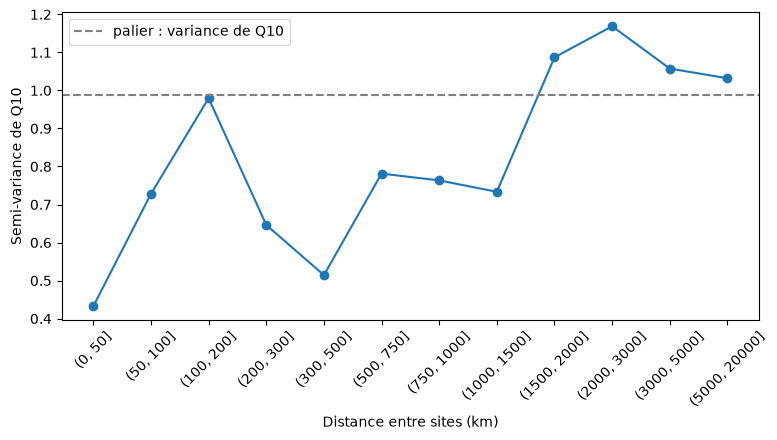

In [37]:
# Graphique : semi-variance moyenne par classe de distance, et palier (variance de Q10)
plt.figure(figsize=(9, 4))
plt.plot(range(len(variogramme)), variogramme["mean"], "o-")
plt.axhline(df.Q10.var(), ls="--", c="grey", label="palier : variance de Q10")
plt.xticks(range(len(variogramme)), [str(c) for c in variogramme.index], rotation=45)
plt.xlabel("Distance entre sites (km)"); plt.ylabel("Semi-variance de Q10"); plt.legend()
plt.show()

**Constat :** la semi-variance est faible sous 50 km (0.43), puis reste le plus souvent entre 0.5 et 0.8 jusqu'à ≈ 1 500 km, avec un pic isolé à 0.98 entre 100 et 200 km (seulement 39 paires). Au-delà de ≈ 1 500 km, elle atteint le palier (≈ 1.0). Des sites distants de moins de ≈ 1 000–1 500 km se ressemblent donc encore un peu. La courbe est bruitée : c'est un ordre de grandeur, pas une mesure précise.

**Décision :** zones = **carrés de 10° × 10°** (≈ 1 100 km du nord au sud), puis validation croisée à 5 plis par zones (`GroupKFold`), répétée 20 fois avec des découpages différents. On vérifie que les conclusions ne changent pas avec des carrés de 5°.

In [38]:
# Fonction : zone (bloc spatial) de chaque site, carré de `taille` degrés de côté
blocs = lambda taille: (df.lat // taille).astype(int).astype(str) + "_" + (df.lon // taille).astype(int).astype(str)

In [39]:
# Nombre de zones et taille de la plus grosse, pour des carrés de 5° et de 10°
pd.DataFrame({f"{t}°": {"zones": blocs(t).nunique(), "plus grosse zone (sites)": blocs(t).value_counts().max()} for t in (5, 10)})

,5°,10°
zones,62,37
plus grosse zone (sites),8,15


In [40]:
# Import : validation croisée par groupes
from sklearn.model_selection import GroupKFold

In [41]:
# Fonction : RMSE en validation croisée spatiale (5 plis par zones de `taille` degrés × 20 répétitions, découpages identiques)
def rmse_spatial(modele, X, taille=10):
    return np.concatenate([-cross_val_score(modele, X, df.Q10, cv=GroupKFold(5, shuffle=True, random_state=s), groups=blocs(taille), scoring="neg_root_mean_squared_error") for s in range(20)])

**Constat :** 37 zones de 10°, la plus grosse contenant 15 sites (11 %). Chaque pli de test retire donc environ 7 zones entières, soit ≈ 26 sites.

### Étape 3 — Comparaison des deux encodages de la végétation

**Objectif :** comparer le one-hot des biomes (après regroupement) à une typologie plus grossière.

**Raisonnement :**
- **Encodage A : one-hot des 7 biomes** restants après le regroupement de l'étape 1.
- **Encodage B : typologie en 3 classes**, définie pour les 14 biomes RESOLVE (y compris ceux sans site, pour la future carte) :
  - *forêts extratropicales* : forêts tempérées feuillues et mixtes, forêts tempérées de conifères, forêts boréales, **méditerranéen** (6 de nos 7 sites méditerranéens sont dans des écorégions forestières) ;
  - *forêts tropicales* : forêts tropicales humides, sèches et de conifères, mangroves ;
  - *végétation ouverte* : prairies et savanes tempérées et tropicales, prairies de montagne, déserts, prairies inondables, toundra.
- Modèle : Ridge sur les 11 candidats numériques, plus l'un ou l'autre encodage. On compare aussi au modèle **sans végétation** et aux références (Q10 = 2.0, moyenne).
- Évaluation : validation croisée spatiale de l'étape 2 (zones de 10°).

In [42]:
# Rattachement validé des biomes rares (étape 1)
regroupement = {rares[0]: tropical, rares[1]: candidats[1]}

In [43]:
# Typologie en 3 classes pour les 14 biomes RESOLVE
typologie = {
    "Temperate Broadleaf & Mixed Forests": "forêts extratropicales", "Temperate Conifer Forests": "forêts extratropicales",
    "Boreal Forests/Taiga": "forêts extratropicales", "Mediterranean Forests, Woodlands & Scrub": "forêts extratropicales",
    "Tropical & Subtropical Moist Broadleaf Forests": "forêts tropicales", "Tropical & Subtropical Dry Broadleaf Forests": "forêts tropicales",
    "Tropical & Subtropical Coniferous Forests": "forêts tropicales", "Mangroves": "forêts tropicales",
    "Temperate Grasslands, Savannas & Shrublands": "végétation ouverte", "Tropical & Subtropical Grasslands, Savannas & Shrublands": "végétation ouverte",
    "Montane Grasslands & Shrublands": "végétation ouverte", "Deserts & Xeric Shrublands": "végétation ouverte",
    "Flooded Grasslands & Savannas": "végétation ouverte", "Tundra": "végétation ouverte",
}

In [44]:
# Nombre de sites par classe de la typologie
df.biome.map(typologie).value_counts()

biome
forêts extratropicales    101
forêts tropicales          17
végétation ouverte         13
Name: count, dtype: int64

In [45]:
# Trois versions de X : candidats numériques seuls, + encodage A, + encodage B
num = ["lat", "lon", "MAT_public", "MAP_public", "pH_public", "N515", "clay", "sand", "CN", "SWC_mean", "SWC_warm_rel"]
X_versions = {
    "sans végétation": df[num],
    "A : one-hot 7 biomes": df[num].join(pd.get_dummies(df.biome.replace(regroupement), dtype=float)),
    "B : typologie 3 classes": df[num].join(pd.get_dummies(df.biome.map(typologie), dtype=float)),
}

In [46]:
# RMSE moyen en validation croisée spatiale (zones de 10°) : références et Ridge avec chaque version de X
resultats = {f"Q10 = {Q10_REFERENCE}": rmse_spatial(DummyRegressor(strategy="constant", constant=Q10_REFERENCE), df[num]), "moyenne": rmse_spatial(DummyRegressor(), df[num])}
resultats.update({f"Ridge, {k}": rmse_spatial(ridge, X) for k, X in X_versions.items()})
pd.Series({k: v.mean() for k, v in resultats.items()}).round(3)

Q10 = 2.0                         1.083
moyenne                           0.980
Ridge, sans végétation            0.934
Ridge, A : one-hot 7 biomes       0.969
Ridge, B : typologie 3 classes    0.955
dtype: float64

In [47]:
# Comparaisons pli par pli : écart moyen de RMSE, et part des plis où la première version fait mieux
for a, b in [("B : typologie 3 classes", "A : one-hot 7 biomes"), ("B : typologie 3 classes", "sans végétation"), ("A : one-hot 7 biomes", "sans végétation")]:
    d = resultats[f"Ridge, {a}"] - resultats[f"Ridge, {b}"]
    print(f"{a} vs {b} : écart {d.mean():+.3f} | mieux dans {(d < 0).mean():.0%} des plis")

B : typologie 3 classes vs A : one-hot 7 biomes : écart -0.014 | mieux dans 63% des plis
B : typologie 3 classes vs sans végétation : écart +0.021 | mieux dans 35% des plis
A : one-hot 7 biomes vs sans végétation : écart +0.035 | mieux dans 24% des plis


In [48]:
# Robustesse : RMSE moyen du Ridge avec des zones de 5°
pd.Series({k: rmse_spatial(ridge, X, taille=5).mean() for k, X in X_versions.items()}).round(3)

sans végétation            0.937
A : one-hot 7 biomes       0.968
B : typologie 3 classes    0.951
dtype: float64

**Constat :**
- **B fait mieux que A** : 0.955 contre 0.969, et mieux dans 63 % des plis. Le résultat est le même avec des zones de 5°.
- **Mais aucun des deux n'aide le Ridge** : sans végétation, il fait 0.934. A dégrade l'erreur de 0.035, B de 0.021. Moins il y a de catégories, moins l'encodage dégrade : les catégories ajoutent surtout du bruit.
- **En passant** : en validation croisée spatiale, le Ridge sans végétation (0.934) fait 14 % d'erreur en moins que Q10 = 2.0 (1.083), et mieux que la moyenne (0.980). Mais la moyenne seule fait déjà 9.5 % de moins que 2.0 : l'essentiel de l'avance sur 2.0 vient du niveau moyen de Q10, et les variables n'apportent qu'un supplément modeste.

**Pourquoi la végétation n'aide-t-elle pas ?** On teste si la typologie se déduit du climat et du sol (régression logistique en validation croisée). Si c'était le cas, elle n'apporterait aucune information nouvelle.

In [49]:
# Imports : classification par régression logistique, validation croisée stratifiée
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

In [50]:
# Classe de végétation prédite à partir des 9 variables environnementales, en validation croisée
classe = df.biome.map(typologie)
predite = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)), df[env], classe, cv=StratifiedKFold(5, shuffle=True, random_state=0))

In [51]:
# Tableau : vraie classe (lignes) contre classe prédite (colonnes)
pd.crosstab(classe, predite, rownames=["vraie classe"], colnames=["classe prédite"])

classe prédite,forêts extratropicales,forêts tropicales,végétation ouverte
vraie classe,,,
forêts extratropicales,95,1,5
forêts tropicales,5,12,0
végétation ouverte,8,1,4


In [52]:
# Sites de la classe « végétation ouverte » : nom, biome et Q10
df[classe == "végétation ouverte"][["site", "biome", "Q10"]]

,site,biome,Q10
15,11897_US-ONF-NAR,"Temperate Grasslands, Savannas & Shrublands",2.916199
35,dig_Zhao2019_NamCo,Montane Grasslands & Shrublands,2.080000
42,new_cosore_SCOTT_WKG_trenched,Deserts & Xeric Shrublands,1.545448
44,paper_94,"Temperate Grasslands, Savannas & Shrublands",1.258674
49,1639_US-SET-CK,"Temperate Grasslands, Savannas & Shrublands",1.877145
50,dig_Peng2015_Beiluhe,Montane Grasslands & Shrublands,3.492000
51,4174_US-KFF-UCCK,"Temperate Grasslands, Savannas & Shrublands",2.081735
56,paper_112,Montane Grasslands & Shrublands,4.837370
68,paper_85,Montane Grasslands & Shrublands,5.592568
70,new_15204_Wang2021_Haibei_warming_control,Montane Grasslands & Shrublands,2.514479


**Constat :**
- La typologie ne se déduit qu'**en partie** du climat et du sol : 85 % de sites bien classés, contre 77 % en prédisant toujours la classe majoritaire. Les forêts tropicales sont bien reconnues (12 sur 17), mais la végétation ouverte très mal (4 sur 13).
- La raison apparaît dans la liste : **le biome décrit la végétation naturelle de la région, pas celle de la parcelle mesurée.** Le site `7587_CN-SFC-…` est composé de plantations de mélèzes (*Larix*) et de pins (*Pinus*), mais il est classé en prairie. Plusieurs sites du sud-est des États-Unis sont classés en « savanes de conifères ». La classe « végétation ouverte » mélange donc de vraies prairies (plateau tibétain) et des forêts.
- La variable de végétation est ainsi **bruitée au niveau des sites** : c'est la principale explication de son absence d'apport.

#### Conclusion des étapes 2 et 3

- **Protocole retenu pour toute la suite** : validation croisée spatiale, 5 plis par zones de 10° × 10°, répétée 20 fois.
- **Encodage** : la typologie en 3 classes (B) est préférable au one-hot des biomes (A).
- **Mais la végétation, telle que mesurée par les biomes, n'améliore pas le modèle linéaire.**

**Décision proposée :** garder la typologie B comme seule variable de végétation candidate pour le LASSO, qui décidera de la conserver ou non. Abandonner le one-hot des biomes.

**Piste :** remplacer le biome (végétation régionale potentielle) par une carte d'**occupation du sol réelle** (par exemple MODIS Land Cover, disponible dans Earth Engine). Elle décrirait la végétation effectivement présente au site, et serait plus proche des types de végétation (PFT) utilisés par ORCHIDEE.

**Décision (validée par l'équipe)** : la typologie en 3 classes est la variable de végétation candidate ; le one-hot des biomes est abandonné.

### Étape 4 — Table de modélisation (`dataset_v4.csv`)

**Objectif :** figer, dans une table unique, les choix validés par l'équipe, pour que tous les modèles partent exactement des mêmes données.

**Décisions appliquées :**
- **cible : log(Q10)**. C'est directement la pente mesurée (Q10 = e^(10·β), donc log Q10 = 10·β), et les prédictions restent positives même en extrapolant. Les erreurs sont toujours mesurées sur l'échelle de Q10 ;
- **MAP et N515 passés au logarithme** (distributions asymétriques ; sans effet pour les modèles à arbres) ;
- **végétation : typologie en 3 classes** ;
- **zone spatiale (carré de 10°)** de chaque site, pour la validation croisée ;
- pas de pondération par `n_mesures` (chaque lieu compte autant) ; les valeurs extrêmes de Q10 sont gardées.

`MAP_public` reste dans la table sous sa forme brute : la référence Hacopian l'utilise ainsi. La correspondance des 14 biomes vers les 3 classes est enregistrée à part, pour la future carte.

In [53]:
# Table de modélisation : identifiants, cible, zone spatiale et candidats transformés
v4 = df[["site", "source", "study", "Q10", "lat", "lon", "MAT_public", "MAP_public", "pH_public", "clay", "sand", "CN", "SWC_mean", "SWC_warm_rel"]].assign(
    logMAP=np.log(df.MAP_public), logN515=np.log(df.N515), typologie=df.biome.map(typologie), log_Q10=np.log(df.Q10), bloc=blocs(10))

In [54]:
# Sauvegarde de la table de modélisation et de la correspondance biome → typologie (14 biomes)
v4.to_csv("../data/dataset_v4.csv", index=False)
pd.Series(typologie, name="typologie").rename_axis("biome").to_csv("../data/typologie_biomes.csv")

### Étape 5 — Deux contrôles avant la modélisation

**Objectif :** vérifier deux points qui pourraient fausser la suite.
1. **Retour à l'échelle de Q10.** Un modèle entraîné sur log(Q10), puis ramené à Q10 par exponentielle, prédit une médiane plutôt qu'une moyenne. Cela peut le pénaliser en RMSE. La correction de Duan multiplie la prédiction par la moyenne des exp(résidus) d'entraînement. Est-elle nécessaire ?
2. **Biais selon la source des mesures.** Le Q10 médian des sites `mgrsd` est plus élevé (2.74) que celui des autres sources (≈ 2.25). Si c'était un effet de méthode de mesure, il ne serait pas cartographiable.

**Raisonnement :** on utilise désormais les fonctions communes du protocole (`src/protocole.py`) : découpages spatiaux identiques pour tous les modèles, et évaluation sur l'échelle de Q10.

In [55]:
# Import des fonctions communes du protocole (dossier src/) et de clone (copie vierge d'un modèle)
from src.protocole import decoupages_spatiaux, evaluer, resumer, lasso_spatial
from sklearn.base import clone

In [56]:
# Découpages de la validation croisée spatiale (zones de 10°, 5 plis × 20 répétitions), identiques pour toute la suite
decoupages = decoupages_spatiaux(v4.bloc)

In [57]:
# Matrice des 12 candidats : 11 numériques + typologie en one-hot
candidats = ["lat", "lon", "MAT_public", "logMAP", "pH_public", "logN515", "clay", "sand", "CN", "SWC_mean", "SWC_warm_rel"]
X = v4[candidats].join(pd.get_dummies(v4.typologie, dtype=float))

In [58]:
# Fonction : Ridge entraîné sur log(Q10), prédiction ramenée à Q10 par exponentielle, avec ou sans correction de Duan
def ridge_log(tr, te, duan=False):
    m = clone(ridge).fit(X.iloc[tr], v4.log_Q10.iloc[tr])
    facteur = np.mean(np.exp(v4.log_Q10.iloc[tr] - m.predict(X.iloc[tr]))) if duan else 1
    return facteur * np.exp(m.predict(X.iloc[te]))

In [59]:
# RMSE moyen de trois variantes sur les mêmes découpages : log puis exp, log puis exp corrigé, Q10 directement
variantes = {
    "log(Q10), exp": evaluer(ridge_log, decoupages, v4.Q10),
    "log(Q10), exp corrigé (Duan)": evaluer(lambda tr, te: ridge_log(tr, te, duan=True), decoupages, v4.Q10),
    "Q10 direct": evaluer(lambda tr, te: clone(ridge).fit(X.iloc[tr], v4.Q10.iloc[tr]).predict(X.iloc[te]), decoupages, v4.Q10),
}
pd.Series({k: s.rmse.mean() for k, (s, _) in variantes.items()}).round(3)

log(Q10), exp                   0.953
log(Q10), exp corrigé (Duan)    0.950
Q10 direct                      0.952
dtype: float64

**Constat :** les trois variantes sont équivalentes (écarts de l'ordre de 0.003). **Décision :** retour à Q10 par simple exponentielle, sans correction.

In [60]:
# Écart (échelle log) entre Q10 observé et prédit hors échantillon par le Ridge, moyenné sur les 20 répétitions
residus = v4.log_Q10 - np.log(variantes["log(Q10), exp"][1]).mean(axis=0)

In [61]:
# Par source de mesure : Q10 médian, écart moyen une fois le climat et le sol pris en compte, nombre de sites
pd.DataFrame({"Q10 médian": v4.Q10.groupby(v4.source).median(), "écart moyen (log)": residus.groupby(v4.source).mean(), "sites": v4.source.value_counts()}).round(2)

,Q10 médian,écart moyen (log),sites
source,,,
figure,2.23,-0.21,6
holisoils,2.27,-0.09,13
mgrsd,2.74,0.02,23
new paper,2.03,-0.18,2
paper,2.25,0.00,70
root_removal,2.43,0.14,17


In [62]:
# Test de Kruskal-Wallis : les écarts diffèrent-ils selon la source ?
from scipy.stats import kruskal
print(f"p = {kruskal(*[g for _, g in residus.groupby(v4.source)]).pvalue:.2f}")

p = 0.35


**Constat :** le Q10 plus élevé des sites `mgrsd` s'explique par leur environnement : une fois le climat et le sol pris en compte, leur écart moyen est quasi nul (+0.02). Les écarts entre sources ne sont pas significatifs (p = 0.35). **Décision :** on garde toutes les sources, sans correction.

## Partie C — Sélection rigoureuse des variables (LASSO)

**Objectif :** savoir quelles variables portent un signal robuste, et à quel point ce choix est stable.

**Raisonnement :**
- Le LASSO met à zéro les coefficients des variables inutiles (sur variables centrées-réduites, cible log(Q10)).
- Sa pénalité est choisie par une validation croisée **spatiale interne**, à l'intérieur de chaque pli d'entraînement. On teste deux règles : la **règle d'un écart-type** (choix par défaut retenu au départ, qui garde moins de variables) et la **pénalité minimale** (celle qui minimise l'erreur interne).
- On répète la sélection sur les **100 plis d'entraînement** du protocole : la fréquence à laquelle une variable est retenue mesure sa **stabilité**, et la constance du signe de son coefficient sa cohérence.
- Cette étude sert à **comprendre** quelles variables comptent. Elle ne sert pas à choisir les variables des modèles : dans la comparaison des modèles (notebook 04), la sélection sera refaite à l'intérieur de chaque pli.

### Étape 1 — LASSO avec la règle d'un écart-type

In [63]:
# Coefficients du LASSO (règle d'un écart-type) appris sur chacun des 100 plis d'entraînement
coefs_1se = pd.DataFrame([lasso_spatial(X.iloc[tr], v4.log_Q10.iloc[tr], v4.bloc.iloc[tr], regle="1se")[-1].coef_ for _, tr, _ in decoupages], columns=X.columns)

In [64]:
# Répartition du nombre de variables retenues par pli
(coefs_1se != 0).sum(axis=1).value_counts().sort_index()

0    66
1     5
2     4
3    14
4     9
5     2
Name: count, dtype: int64

**Constat :** dans 66 % des plis, la règle d'un écart-type ne retient **aucune variable** : le modèle se réduit à la moyenne. Le signal de chaque variable est faible, si bien que la courbe d'erreur interne est plate et bruitée, et la règle pousse vers le modèle vide. Elle est trop prudente pour nos données.

### Étape 2 — LASSO avec la pénalité minimale

In [65]:
# Coefficients du LASSO (pénalité minimale) appris sur chacun des 100 plis d'entraînement
coefs_min = pd.DataFrame([lasso_spatial(X.iloc[tr], v4.log_Q10.iloc[tr], v4.bloc.iloc[tr], regle="min")[-1].coef_ for _, tr, _ in decoupages], columns=X.columns)

In [66]:
# Stabilité : fréquence de sélection de chaque variable, et part des sélections où son coefficient est positif
stabilite = pd.DataFrame({"fréquence": (coefs_min != 0).mean(), "part positive": (coefs_min > 0).sum() / (coefs_min != 0).sum()}).sort_values("fréquence", ascending=False).round(2)
stabilite

,fréquence,part positive
logN515,0.99,1.00
SWC_warm_rel,0.97,1.00
lon,0.96,1.00
MAT_public,0.80,0.02
végétation ouverte,0.70,1.00
lat,0.27,1.00
logMAP,0.21,0.00
forêts tropicales,0.20,0.00
CN,0.16,0.00
sand,0.13,0.85


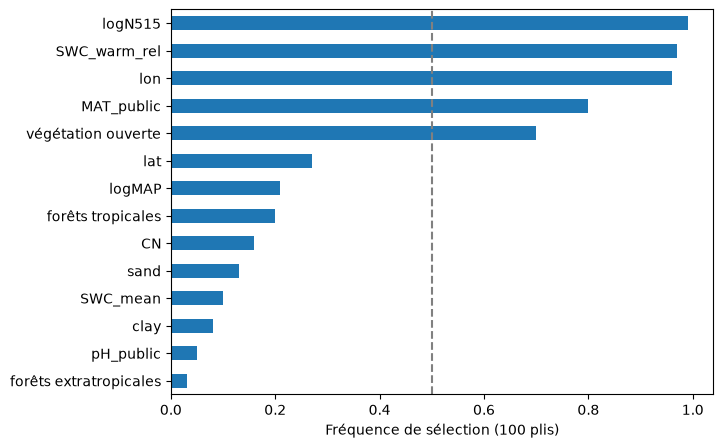

In [67]:
# Graphique : fréquence de sélection de chaque variable sur les 100 plis (pointillés : 50 %)
stabilite["fréquence"].plot.barh(figsize=(7, 5)).invert_yaxis()
plt.axvline(0.5, ls="--", c="grey"); plt.xlabel("Fréquence de sélection (100 plis)")
plt.show()

In [68]:
# Répartition du nombre de variables retenues par pli
(coefs_min != 0).sum(axis=1).value_counts().sort_index()

0      1
3      5
4     19
5     34
6     13
7     12
8     12
9      1
11     1
13     2
Name: count, dtype: int64

**Constat :**
- **Un noyau de 5 variables stables**, retenues dans au moins 70 % des plis, avec un signe constant (dans au moins 98 % des sélections) :
  - `logN515` (99 %, +) : plus d'azote, Q10 plus élevé ;
  - `SWC_warm_rel` (97 %, +) : un sol sec en été fait baisser Q10 (cas méditerranéen) ;
  - `lon` (96 %, +) : Q10 plus élevé en Asie de l'Est, à toutes choses égales par ailleurs ;
  - `MAT_public` (80 %, −) : climat plus chaud, Q10 plus faible (comme chez Hacopian) ;
  - `végétation ouverte` (70 %, +) : prairies et savanes, Q10 plus élevé (comme chez Hacopian).
- Les autres variables sont rarement retenues (au plus 27 % des plis). **Le pH, central chez Hacopian, n'est retenu que dans 5 % des plis.**
- Médiane : 5 variables retenues par pli.

### Étape 3 — Performance en validation croisée spatiale

On compare les deux règles au Ridge (toutes les variables, sans sélection) et aux références (Q10 = 2.0 et moyenne). Toutes les prédictions sont évaluées sur l'échelle de Q10.

In [69]:
# Performance de chaque approche sur les mêmes découpages spatiaux
perf = {
    f"Q10 = {Q10_REFERENCE}": evaluer(lambda tr, te: np.full(len(te), Q10_REFERENCE), decoupages, v4.Q10),
    "moyenne": evaluer(lambda tr, te: np.full(len(te), v4.Q10.iloc[tr].mean()), decoupages, v4.Q10),
    "LASSO (règle 1-SE)": evaluer(lambda tr, te: np.exp(lasso_spatial(X.iloc[tr], v4.log_Q10.iloc[tr], v4.bloc.iloc[tr], regle="1se").predict(X.iloc[te])), decoupages, v4.Q10),
    "LASSO (pénalité minimale)": evaluer(lambda tr, te: np.exp(lasso_spatial(X.iloc[tr], v4.log_Q10.iloc[tr], v4.bloc.iloc[tr], regle="min").predict(X.iloc[te])), decoupages, v4.Q10),
    "Ridge (toutes les variables)": variantes["log(Q10), exp"],
}

In [70]:
# Tableau récapitulatif : RMSE, MAE, R² et gain par rapport à la valeur fixe de référence
rmse_ref = perf[f"Q10 = {Q10_REFERENCE}"][0].rmse.mean()
pd.DataFrame({k: resumer(s, o, v4.Q10, rmse_ref) for k, (s, o) in perf.items()}).T.round(3)

,RMSE,MAE,R²,gain vs référence (%)
Q10 = 2.0,1.083,0.791,-0.264,0.000
moyenne,0.980,0.748,-0.033,9.536
LASSO (règle 1-SE),0.990,0.726,-0.064,8.551
LASSO (pénalité minimale),0.954,0.689,0.001,11.863
Ridge (toutes les variables),0.953,0.691,0.012,12.026


**Constat :**
- La règle d'un écart-type fait **moins bien que la moyenne** (0.990 contre 0.980) : réduite le plus souvent au modèle vide, elle perd le peu de signal disponible.
- La pénalité minimale fait aussi bien que le Ridge (≈ 0.954), soit **≈ 12 % d'erreur en moins que Q10 = 2.0**, avec 5 variables au lieu de 14. La moyenne seule fait déjà 9.5 % de moins que 2.0 : les variables apportent ≈ 2.5 points de plus.
- **Le R² reste proche de 0** : en prédisant des régions nouvelles, les modèles linéaires n'expliquent qu'une très faible part de la variabilité de Q10. Le gain par rapport à 2.0 est net, mais il vient surtout du niveau moyen de Q10 ; ce que les variables apportent en plus est modeste.

**Décision (validée par l'équipe) :** utiliser la **pénalité minimale** pour la sélection LASSO de la variante V2 du notebook 04 (et non la règle d'un écart-type, choisie par défaut au départ).

### Étape 4 — Semi-variogramme des résidus

**Objectif :** vérifier si, une fois le climat et le sol pris en compte, les résidus de sites voisins se ressemblent encore. Si c'est le cas, l'information spatiale (krigeage, coordonnées) peut encore apporter quelque chose. Cela permet aussi de vérifier que des zones de 10° restent adaptées.

In [71]:
# Résidus du LASSO (pénalité minimale) : Q10 observé − prédiction hors échantillon moyenne sur les 20 répétitions
residus_lasso = v4.Q10.values - perf["LASSO (pénalité minimale)"][1].mean(axis=0)

In [72]:
# Semi-variogramme des résidus, avec les mêmes paires et classes de distance qu'à l'étape 2 de la partie B
vario_res = pd.Series((0.5 * (residus_lasso[:, None] - residus_lasso) ** 2)[paires]).groupby(classes, observed=True).mean()

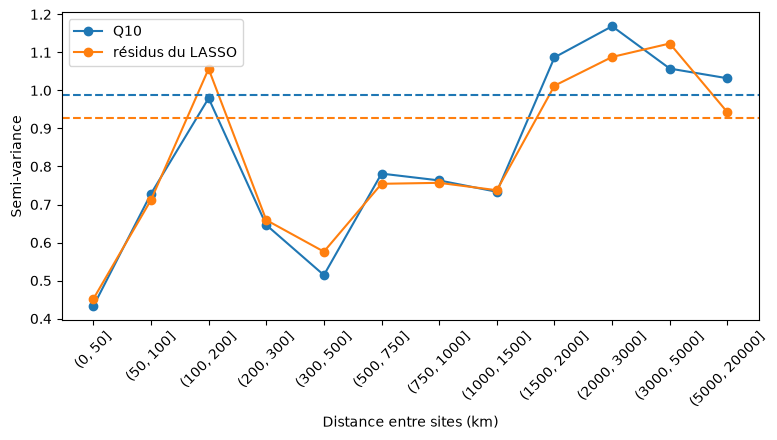

In [73]:
# Graphique : semi-variogrammes de Q10 et des résidus du LASSO, avec leurs paliers (pointillés)
plt.figure(figsize=(9, 4))
plt.plot(range(len(variogramme)), variogramme["mean"], "o-", label="Q10")
plt.plot(range(len(vario_res)), vario_res, "o-", label="résidus du LASSO")
plt.axhline(df.Q10.var(), ls="--", c="C0"); plt.axhline(residus_lasso.var(ddof=1), ls="--", c="C1")
plt.xticks(range(len(variogramme)), [str(c) for c in variogramme.index], rotation=45)
plt.xlabel("Distance entre sites (km)"); plt.ylabel("Semi-variance"); plt.legend()
plt.show()

**Constat :**
- Le semi-variogramme des résidus est **presque identique** à celui de Q10, et les résidus ont presque la même variance que Q10 (0.93 contre 0.99). La structure spatiale (des sites proches se ressemblent jusqu'à ≈ 1 000–1 500 km) **n'est pas expliquée** par nos variables : elle reste entière dans les résidus.
- Conséquence 1 : les **zones de 10° restent adaptées** à la validation croisée.
- Conséquence 2 : une part de la variabilité de Q10 est structurée dans l'espace sans être liée au climat ni au sol. Des modèles qui exploitent la proximité géographique (GP avec coordonnées, krigeage des résidus) pourraient en tirer parti **près de nos sites**, mais pas dans les régions sans aucune mesure (Afrique, Amérique du Sud), où cette information n'existe pas.

## Conclusion de la partie C

- **Noyau stable** : `logN515` (+), `SWC_warm_rel` (+), `lon` (+), `MAT_public` (−), `végétation ouverte` (+). C'est cohérent avec Hacopian pour MAT et la végétation ouverte ; nouveau pour l'azote et l'humidité estivale. Le pH n'est presque jamais retenu.
- **Variables rarement retenues** : `lat`, `logMAP`, `forêts tropicales`, `CN`, `sand`, `SWC_mean`, `clay`, `pH_public`, `forêts extratropicales`. On ne les exclut **pas** de la comparaison des modèles : la variante V1 garde les 12 candidats, car un modèle non linéaire peut exploiter une variable que le LASSO juge inutile linéairement.
- **Gain d'un modèle linéaire sur 2.0** : ≈ 12 % de RMSE en validation croisée spatiale, dont ≈ 9.5 points obtenus par la simple moyenne ; R² proche de 0. C'est la base que les modèles non linéaires devront dépasser.
- **Structure spatiale non expliquée**, à garder en tête pour le GP et le krigeage.

**Décision (validée par l'équipe) :** sélection de la variante V2 (notebook 04) par LASSO avec **pénalité minimale**.